# 29 · Target transforms

Should a model learn a series or its logarithm? Generate a series whose seasonal swing grows with its level, fit the same AR(1) to seasonal differences with and without taking logs first, and compare both forecasts on the original scale across independent series.

## Run this notebook

From the repository root, install `python -m pip install -e '.[notebooks]'`, then launch `python -m jupyterlab notebooks`. Use that Python kernel and run all cells in order. See the [notebook guide](README.md). This application is self-contained and runs locally. The repeated comparison uses 60 series, 24 horizons, and 400 samples.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import timegym
from timegym import Case, ForecastTask, GaussianAR1Forecaster, Pipeline, Scenario, SimulationReference
from timegym.diagnostics import evaluate_forecast
from timegym.statistics import paired_t_interval
from timegym.target import BoxCoxTransform, ComposedTransform, DifferenceTransform, LogTransform

%matplotlib inline
plt.rcParams.update({"figure.figsize": (12, 4), "figure.dpi": 110, "font.size": 11,
                     "figure.facecolor": "white", "axes.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": False, "legend.frameon": False, "axes.titlelocation": "left"})
COLORS = {"Seasonal difference": "#D55E00", "Log, then seasonal difference": "#0000CC"}
print(f"TimeGym {timegym.__version__} | NumPy {np.__version__} | pandas {pd.__version__}")

TimeGym 1.0.0 | NumPy 2.5.4 | pandas 3.1.0


## Build a multiplicative seasonal series

The `composite` scenario adds a line, a sinusoid, and Gaussian white noise. Read its values as logarithms. Exponentiating them gives a level that grows by a fixed percentage each month and a season whose amplitude is proportional to that level.

The reference stays exact. The future logarithms are Gaussian with known mean `m` and covariance `C`, so the future values are log-normal: their mean is `exp(m + v/2)`, where `v` is the diagonal of `C`, and their samples are exponentiated reference samples. The reference is privileged: it knows the generator, while the models see only the context.

In [2]:
HORIZON = 24
N_SAMPLES = 400
log_scenario = Scenario("composite", context_length=120, horizon=HORIZON, parameters={
    "intercept": np.log(100.), "slope": .012, "amplitude": .25, "period": 12., "sigma": .08})


def multiplicative_case(seed):
    """Exponentiate one composite case; the log-normal reference stays exact."""
    log_case = log_scenario.generate(seed=seed)
    log_reference = log_case.reference
    mean = np.exp(log_reference.mean + log_reference.variance / 2)
    covariance = np.outer(mean.ravel(), mean.ravel()) * np.expm1(log_reference.covariance)
    reference = SimulationReference(
        mean=mean, variance=np.diag(covariance).reshape(mean.shape), covariance=covariance,
        index=log_reference.index, target_names=log_reference.target_names,
        sampler=lambda n_samples, seed: np.exp(log_reference.sample(n_samples, seed)))
    return Case(task=ForecastTask(np.exp(log_case.task.context), log_case.task.future_index),
                observed=np.exp(log_case.observed), reference=reference,
                manifest={**log_case.manifest, "values": "exp(composite)"})


case = multiplicative_case(seed=3)
first_season = case.task.context.iloc[:12, 0]
last_season = case.task.context.iloc[-12:, 0]
display(pd.DataFrame({"mean level": [first_season.mean(), last_season.mean()],
                      "seasonal range": [np.ptp(first_season), np.ptp(last_season)]},
                     index=["first context year", "last context year"]).round(1))

,mean level,seasonal range
first context year,113.7,57.8
last context year,398.4,200.9


## Fit the same model twice

An AR(1) on raw levels cannot represent the season, so both pipelines take a 12-month difference before fitting. One takes logarithms first. Each transform is fitted on its own context, the model sees only the transformed values, and the forecast is inverted before it is returned. The configuration records the transform, so a saved report can rebuild it.

In [3]:
pipelines = {
    "Seasonal difference": Pipeline(GaussianAR1Forecaster(n_samples=N_SAMPLES, seed=29),
                                    target_transform=DifferenceTransform(lag=12)),
    "Log, then seasonal difference": Pipeline(
        GaussianAR1Forecaster(n_samples=N_SAMPLES, seed=29),
        target_transform=ComposedTransform([LogTransform(), DifferenceTransform(lag=12)])),
}
forecasts = {name: pipeline.predict(case.task.context, case.task.future_index)
             for name, pipeline in pipelines.items()}
for forecast in forecasts.values():
    assert forecast.validate(case.task) == []
    assert forecast.samples.shape == (N_SAMPLES, HORIZON, 1)
config = pipelines["Log, then seasonal difference"].to_config()
assert config["replayable"] and Pipeline.from_config(config).to_config() == config
display(config["target_transform"])

{'kind': 'builtin',
 'class': 'ComposedTransform',
 'parameters': {'transforms': [{'kind': 'builtin',
    'class': 'LogTransform',
    'parameters': {}},
   {'kind': 'builtin',
    'class': 'DifferenceTransform',
    'parameters': {'order': 1, 'lag': 12}}]}}

## Compare the forecasts on the original scale

Crosses are point forecasts; gray dots are observations. Bands are 80% marginal intervals from each forecast's own quantiles, and the thin gray curve is the privileged log-normal mean. Everything is in the original units: the inverse transforms ran before plotting.

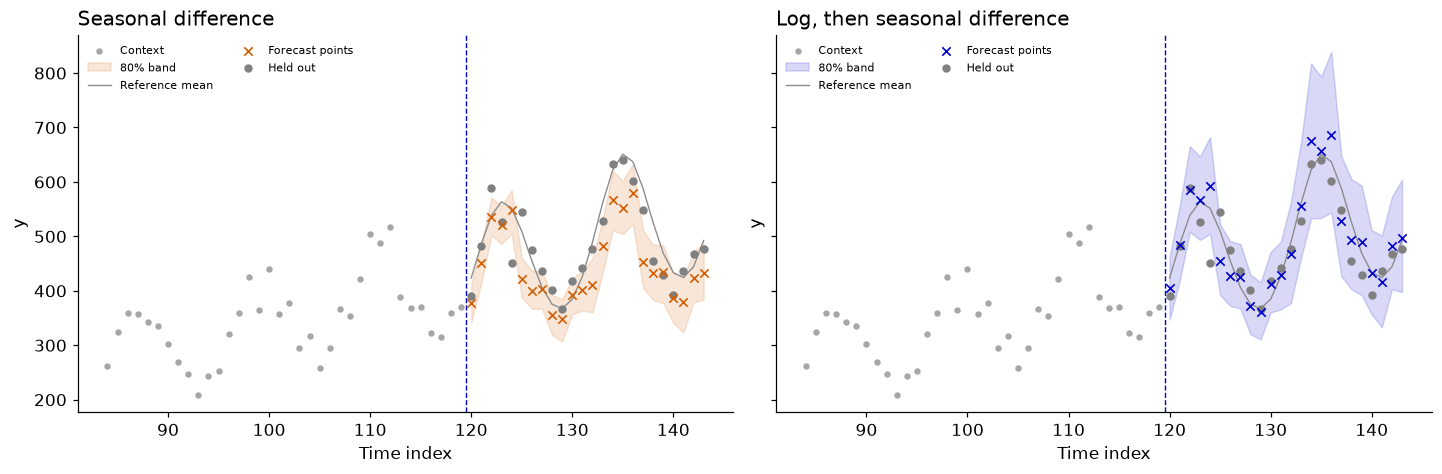

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharex=True, sharey=True, constrained_layout=True)
context = case.task.context.iloc[-36:]
future = case.task.future_index
for ax, (name, forecast) in zip(axes, forecasts.items()):
    ax.scatter(context.index, context.iloc[:, 0], color="0.65", s=10, label="Context")
    ax.fill_between(future, forecast.quantiles[:, 0, 0], forecast.quantiles[:, 0, -1],
                    color=COLORS[name], alpha=.15, label="80% band")
    ax.plot(future, case.reference.mean[:, 0], color="0.55", linewidth=.9, label="Reference mean")
    ax.scatter(future, forecast.point[:, 0], marker="x", color=COLORS[name], s=30, linewidths=1.1,
               label="Forecast points", zorder=4)
    ax.scatter(future, case.observed.iloc[:, 0], color="0.5", s=20, label="Held out", zorder=3)
    ax.axvline(future[0] - .5, color="#0000CC", linestyle="--", linewidth=.9)
    ax.set(title=name, xlabel="Time index", ylabel="y")
    ax.legend(fontsize=7.5, loc="upper left", ncol=2)
plt.show()

Differencing raw values adds a yearly change, estimated from the whole context, to last year's value. Under proportional growth the true change is larger at the peaks than in the troughs, and larger now than early in the context, so this forecast falls short, most of all at the peaks, and its band cannot widen with the level. Logs make the season additive before the difference, so the log forecast follows the swing and its band widens with the level.

## Measure across independent series

Generate 60 independent series, fit both pipelines to each context, and score the inverted forecasts against the held-out values. CRPS scores the sample paths marginally; MSE scores the points. Both forecasts must pass the output contract before any score is calculated. Each series is one replication; its 24 horizons are not 24 more.

In [5]:
N_CASES = 60
records = []
for seed in range(1000, 1000 + N_CASES):
    series_case = multiplicative_case(seed)
    for name, pipeline in pipelines.items():
        result = evaluate_forecast(series_case, pipeline.predict(series_case.task.context,
                                                                 series_case.task.future_index))
        assert {d.name: d.status for d in result.diagnostics}["forecast_contract"] == "PASS"
        records.append({"seed": seed, "pipeline": name, "CRPS": result.metrics["crps"],
                        "MSE": result.metrics["mse"], "Mean-reference MSE": result.metrics["mean_reference_mse"],
                        "80% coverage": result.metrics["interval_coverage"]})
scores = pd.DataFrame(records)
display(scores.groupby("pipeline", sort=False)[["CRPS", "MSE", "Mean-reference MSE", "80% coverage"]]
        .mean().round(3))

,CRPS,MSE,Mean-reference MSE,80% coverage
pipeline,,,,
Seasonal difference,46.886,5951.055,3965.830,0.456
"Log, then seasonal difference",32.674,3432.948,1712.456,0.859


,mean difference,lower 95%,upper 95%,independent series
CRPS,-14.211,-16.301,-12.122,60.0
MSE,-2518.108,-2973.473,-2062.742,60.0
Mean-reference MSE,-2253.374,-2644.141,-1862.606,60.0


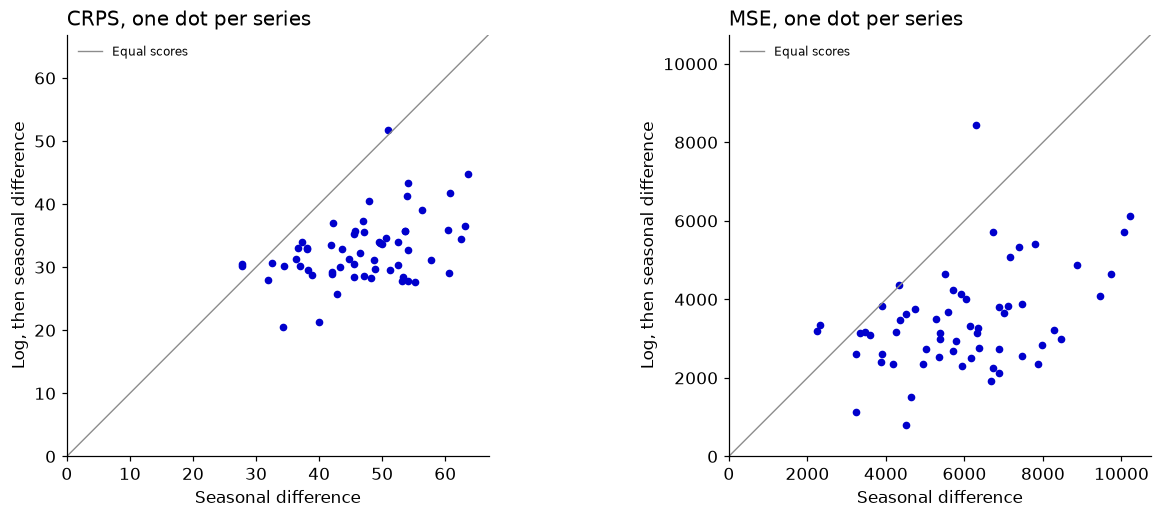

In [6]:
paired = {}
for metric in ("CRPS", "MSE", "Mean-reference MSE"):
    table = scores.pivot(index="seed", columns="pipeline", values=metric)
    paired[metric] = paired_t_interval(table["Log, then seasonal difference"] - table["Seasonal difference"])
display(pd.DataFrame({metric: {"mean difference": interval["mean"], "lower 95%": interval["ci95"][0],
                               "upper 95%": interval["ci95"][1], "independent series": interval["n"]}
                      for metric, interval in paired.items()}).T.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), constrained_layout=True)
for ax, metric in zip(axes, ("CRPS", "MSE")):
    table = scores.pivot(index="seed", columns="pipeline", values=metric)
    ax.scatter(table["Seasonal difference"], table["Log, then seasonal difference"], s=16, color="#0000CC")
    limits = [0, table.max().max() * 1.05]
    ax.plot(limits, limits, color="0.55", linewidth=.9, label="Equal scores")
    ax.set(xlim=limits, ylim=limits, aspect="equal", title=f"{metric}, one dot per series",
           xlabel="Seasonal difference", ylabel="Log, then seasonal difference")
    ax.legend(fontsize=8, loc="upper left")
plt.show()

Dots below the diagonal are series where the log pipeline has the lower loss. The paired differences are means over independent series with Student t intervals; they are descriptive, with no acceptance threshold. Coverage near 80% for the log pipeline is marginal coverage pooled over dependent horizons, not a calibration test.

## Why the mean does not invert

The model's point on the log scale estimates the mean of the future logarithm. Exponentiating it gives `exp(E[log y])`, and because `exp` is convex, Jensen's inequality makes this smaller than `E[y]`. For a Gaussian log-scale law it is exactly the median, below the mean by the factor `exp(v/2)`, where `v` is the log-scale variance. No function of the log-scale mean alone recovers the original-scale mean, because that factor depends on the variance. Quantiles and samples map one to one through `exp`, so TimeGym inverts them and takes the point as the mean of the inverted samples; without samples it uses the inverted median. The table rebuilds the log pipeline by hand and compares both points on the same sample paths.

In [7]:
log_transform, seasonal_difference = LogTransform(), DifferenceTransform(lag=12)
logged = log_transform.fit_transform(case.task.context)
model = GaussianAR1Forecaster(n_samples=N_SAMPLES, seed=29).fit(seasonal_difference.fit_transform(logged))
log_levels = seasonal_difference.inverse_transform(model.predict(case.task.future_index))
restored = log_transform.inverse_transform(log_levels)
np.testing.assert_array_equal(restored.point, forecasts["Log, then seasonal difference"].point)
log_paths = log_levels.samples[:, :, 0]
comparison = pd.DataFrame({
    "exp(mean of log paths)": np.exp(log_paths.mean(axis=0)),
    "mean of exp(log paths)": restored.point[:, 0],
    "ratio": restored.point[:, 0] / np.exp(log_paths.mean(axis=0)),
    "exp(log variance / 2)": np.exp(log_paths.var(axis=0) / 2),
}, index=pd.RangeIndex(1, HORIZON + 1, name="horizon"))
assert (comparison["ratio"] > 1).all()
display(comparison.iloc[[0, 11, 23]].round(4))
box_cox = BoxCoxTransform()
box_cox.fit_transform(case.task.context)
print(f"Box-Cox power estimated on this context: {box_cox.lambdas_[0]:.3f}")

,exp(mean of log paths),mean of exp(log paths),ratio,exp(log variance / 2)
horizon,,,,
1,403.3316,405.8473,1.0062,1.0062
12,425.5784,428.3698,1.0066,1.0065
24,491.4192,497.7607,1.0129,1.0128


Box-Cox power estimated on this context: -0.021


On the same paths the mean of the exponentials always exceeds the exponential of the mean, and their ratio tracks `exp(v/2)`, growing with horizon as the log-scale variance accumulates. Here the gap is about one percent because the noise is small; it is a bias, not sampling error, and more samples would not remove it. `BoxCoxTransform` estimates its power on each context alone; a value near zero means the data favour the logarithm.

## Change one thing

- Replace `LogTransform()` with `BoxCoxTransform()` in the composed transform and compare the scores.
- Raise `sigma` to 0.2 and watch the ratio in the last table grow with the log-scale variance.
- Drop the seasonal difference and fit the AR(1) to logs alone: the model loses the season.
- Set `slope` and `amplitude` to zero, so that nothing scales with the level, and check whether the log still helps.

**Scope.** These results concern one generator and one fitted AR(1), which omits parameter uncertainty; they do not say which transform suits a real series. Coverage and CRPS are marginal, and the reference is privileged information no model has.

Continue with [30 · Reductions](30_reductions.ipynb). Reading: [Box and Cox (1964)](https://doi.org/10.1111/j.2517-6161.1964.tb00553.x).